DATASET: https://www.kaggle.com/datasets/khushikyad001/public-transport-delays-with-weather-and-events

**Public Transit Delays Prediction**

This project uses trip, weather, traffic, and event data to predict whether a public transport trip will be delayed.

**About the Dataset**

The Public Transit Delays with Weather & Traffic dataset has 2,000 rows and 24 columns about trips from 1 January 2023 to 22 January 2023, including transport type, route, origin and destination station, scheduled times, actual delay (departure and arrival), weather condition, temperature, humidity, wind speed, precipitation, event type and attendance, traffic congestion index, holiday, peak hour, weekday, season, and whether the trip was delayed.

**Details about Delayed Column:**
- 0: The trip arrived on time (arrival delay of 5 minutes or less).
- 1: The trip was delayed (arrival delay of more than 5 minutes).

In [1]:
# importing the libraries needed
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

In [2]:
# load the dataset
df = pd.read_csv("/mnt/user-data/uploads/public_transport_delays.csv")
df.head(10)

,trip_id,date,time,transport_type,route_id,origin_station,destination_station,scheduled_departure,scheduled_arrival,actual_departure_delay_min,...,wind_speed_kmh,precipitation_mm,event_type,event_attendance_est,traffic_congestion_index,holiday,peak_hour,weekday,season,delayed
0,T00000,2023-01-01,05:00:00,Tram,Route_15,Station_31,Station_6,05:02:00,05:55:00,12,...,46,13.0,NaN,500,81,0,1,6,Winter,0
1,T00001,2023-01-01,05:15:00,Metro,Route_12,Station_49,Station_32,05:16:00,05:55:00,15,...,11,11.4,NaN,0,53,0,0,6,Autumn,1
2,T00002,2023-01-01,05:30:00,Bus,Route_16,Station_29,Station_42,05:33:00,06:17:00,0,...,31,14.1,Sports,0,67,1,0,6,Autumn,0
3,T00003,2023-01-01,05:45:00,Tram,Route_19,Station_26,Station_18,05:49:00,06:08:00,15,...,41,6.4,NaN,500,84,0,0,6,Winter,1
4,T00004,2023-01-01,06:00:00,Tram,Route_8,Station_18,Station_15,06:00:00,06:35:00,-1,...,30,18.5,NaN,500,46,0,0,6,Spring,1
5,T00005,2023-01-01,06:15:00,Metro,Route_17,Station_32,Station_40,06:15:00,06:56:00,7,...,21,2.3,Protest,0,41,0,0,6,Spring,0
6,T00006,2023-01-01,06:30:00,Bus,Route_5,Station_22,Station_32,06:34:00,07:01:00,8,...,16,6.4,Parade,0,22,1,1,6,Spring,1
7,T00007,2023-01-01,06:45:00,Bus,Route_16,Station_38,Station_9,06:47:00,07:20:00,0,...,19,0.6,NaN,0,85,0,0,6,Spring,1
8,T00008,2023-01-01,07:00:00,Tram,Route_6,Station_17,Station_37,07:01:00,07:59:00,4,...,19,5.4,Concert,500,64,0,0,6,Summer,1
9,T00009,2023-01-01,07:15:00,Train,Route_8,Station_23,Station_10,07:17:00,08:12:00,5,...,42,4.4,NaN,50000,88,0,0,6,Summer,0


## Data Preprocessing

In [3]:
# check for the data type
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   trip_id                     2000 non-null   str    
 1   date                        2000 non-null   str    
 2   time                        2000 non-null   str    
 3   transport_type              2000 non-null   str    
 4   route_id                    2000 non-null   str    
 5   origin_station              2000 non-null   str    
 6   destination_station         2000 non-null   str    
 7   scheduled_departure         2000 non-null   str    
 8   scheduled_arrival           2000 non-null   str    
 9   actual_departure_delay_min  2000 non-null   int64  
 10  actual_arrival_delay_min    2000 non-null   int64  
 11  weather_condition           2000 non-null   str    
 12  temperature_C               2000 non-null   float64
 13  humidity_percent            2000 non-null   

In [4]:
categories = ['transport_type', 'weather_condition', 'event_type', 'season']

In [5]:
# check for the missing value
df.isnull().sum()

trip_id                          0
date                             0
time                             0
transport_type                   0
route_id                         0
origin_station                   0
destination_station              0
scheduled_departure              0
scheduled_arrival                0
actual_departure_delay_min       0
actual_arrival_delay_min         0
weather_condition                0
temperature_C                    0
humidity_percent                 0
wind_speed_kmh                   0
precipitation_mm                 0
event_type                    1173
event_attendance_est             0
traffic_congestion_index         0
holiday                          0
peak_hour                        0
weekday                          0
season                           0
delayed                          0
dtype: int64

Empty `event_type` is first assumed to mean there was no event during the trip -> impute with "None". This assumption is checked below.

In [6]:
# replacing the null values with 'None' in the column 'event_type'
df['event_type'] = df['event_type'].fillna('None')

In [ ]:
# validate the assumption: no event should also mean no attendance
no_event = df['event_type'] == 'None'
print("No event  -> attendance == 0:", (df.loc[no_event, 'event_attendance_est'] == 0).mean())
print("Has event -> attendance > 0 :", (df.loc[~no_event, 'event_attendance_est'] > 0).mean())

No event  -> attendance == 0: 0.6078431372549019
Has event -> attendance > 0 : 0.39177750906892383


- Only 60.8% of trips with an empty `event_type` have 0 attendance; the other 460 trips have attendance above 0 even though no event is recorded.
- Only 39.2% of trips with an event have attendance above 0; 503 event trips have 0 attendance.
- So the assumption is **not supported**: attendance does not match `event_type` (the two columns look independent, another sign of synthetic data). "None" is kept as its own category, but it means "no event type recorded", not "confirmed no event".

In [7]:
# check duplicates and the definition of the target
print("Duplicate trip_id:", df.trip_id.duplicated().sum())
print("Date range:", df.date.min(), "->", df.date.max())
print("delayed == (arrival delay > 5):", ((df.actual_arrival_delay_min > 5).astype(int) == df.delayed).all())

Duplicate trip_id: 0
Date range: 2023-01-01 -> 2023-01-22
delayed == (arrival delay > 5): True


- `delayed` is defined exactly as `actual_arrival_delay_min > 5`. So the delay columns must **not** be used as features to predict `delayed` (target leakage).
- The data covers only 22 days, so "season" cannot represent real seasons.

In [8]:
# create time features and scheduled duration
df['hour'] = pd.to_datetime(df['time'], format='%H:%M:%S').dt.hour
df['day'] = pd.to_datetime(df['date']).dt.day
t = lambda c: pd.to_datetime(df[c], format='%H:%M:%S')
df['sched_duration_min'] = ((t('scheduled_arrival') - t('scheduled_departure')).dt.total_seconds() / 60) % 1440  # handle trips past midnight

In [9]:
# drop unimportant features (identifier, raw time strings)
df.drop(['trip_id', 'date', 'time', 'scheduled_departure', 'scheduled_arrival'], axis=1, inplace=True)

In [10]:
df.describe()

,actual_departure_delay_min,actual_arrival_delay_min,temperature_C,humidity_percent,wind_speed_kmh,precipitation_mm,event_attendance_est,traffic_congestion_index,holiday,peak_hour,weekday,delayed,hour,day,sched_duration_min
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,8.688000,13.318000,15.121350,64.714000,29.300500,9.860700,6420.250000,50.244000,0.089500,0.272000,2.976000,0.749500,11.572000,11.122000,37.003500
std,6.268118,9.289727,11.479424,20.334747,17.264015,5.781373,15198.306129,29.225751,0.285535,0.445101,1.990328,0.433409,6.903669,6.017077,11.341243
min,-2.000000,-3.000000,-5.000000,30.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,16.000000
25%,3.000000,5.000000,5.100000,46.000000,15.000000,4.900000,0.000000,25.000000,0.000000,0.000000,1.000000,0.000000,6.000000,6.000000,27.000000
50%,9.000000,13.000000,15.300000,65.000000,29.000000,9.700000,0.000000,50.000000,0.000000,0.000000,3.000000,1.000000,12.000000,11.000000,37.000000
75%,14.000000,21.000000,24.800000,83.000000,45.000000,14.800000,2000.000000,76.000000,0.000000,1.000000,5.000000,1.000000,18.000000,16.000000,47.000000
max,19.000000,29.000000,35.000000,99.000000,59.000000,20.000000,50000.000000,99.000000,1.000000,1.000000,6.000000,1.000000,23.000000,22.000000,59.000000


In [11]:
# check the distribution of each categorical feature for the target (as % delayed)
for i in categories:
    print(df.groupby(i)['delayed'].agg(n='size', pct_delayed='mean').round(3))
    print("\n")

                  n  pct_delayed
transport_type                  
Bus             525        0.752
Metro           491        0.713
Train           493        0.769
Tram            491        0.764


                     n  pct_delayed
weather_condition                  
Clear              343        0.755
Cloudy             325        0.735
Fog                331        0.731
Rain               321        0.757
Snow               343        0.752
Storm              337        0.766


               n  pct_delayed
event_type                   
Concert      203        0.734
Festival     221        0.747
None        1173        0.755
Parade       105        0.762
Protest       86        0.767
Sports       212        0.722


          n  pct_delayed
season                  
Autumn  480        0.756
Spring  502        0.749
Summer  524        0.731
Winter  494        0.763




- The overall delay rate is 75%, and it hardly changes across groups: transport type 71-77% (Metro lowest, Train highest), weather 73-77%, season 73-76%, event type 72-77% (Sports lowest, Protest highest).
- Differences are small compared with the 75% average, so no category stands out clearly.

## EDA

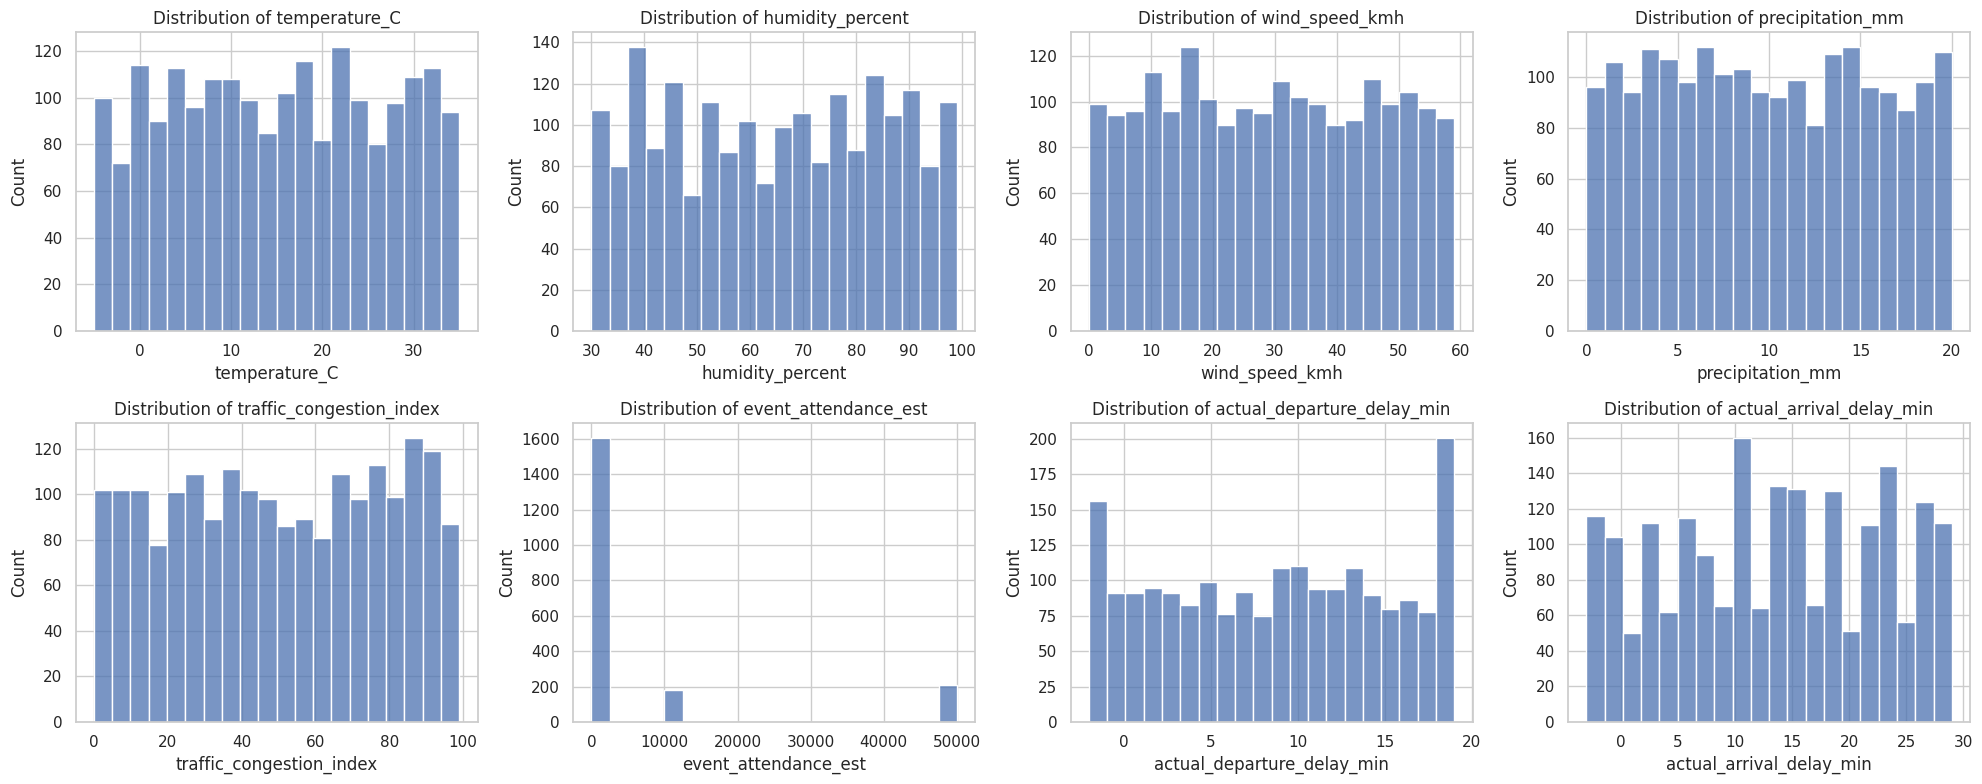

In [12]:
# distribution of each numeric feature
numeric = ['temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm',
           'traffic_congestion_index', 'event_attendance_est', 'actual_departure_delay_min', 'actual_arrival_delay_min']
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, i in zip(axes.flatten(), numeric):
    sns.histplot(df[i], bins=20, ax=ax)
    ax.set_title(f"Distribution of {i}")
plt.tight_layout()
plt.show()

- Weather and traffic variables are spread almost uniformly across their ranges (temperature -5 to 35, humidity 30-99, wind 0-59, congestion 0-99).
- Event attendance is 0 for about 61% of trips; otherwise it takes a few fixed values (500, 2,000, 10,000, 50,000), regardless of `event_type`.
- Arrival delay ranges from -3 to 29 minutes; the 5-minute threshold splits the data into 75% delayed vs 25% on time.

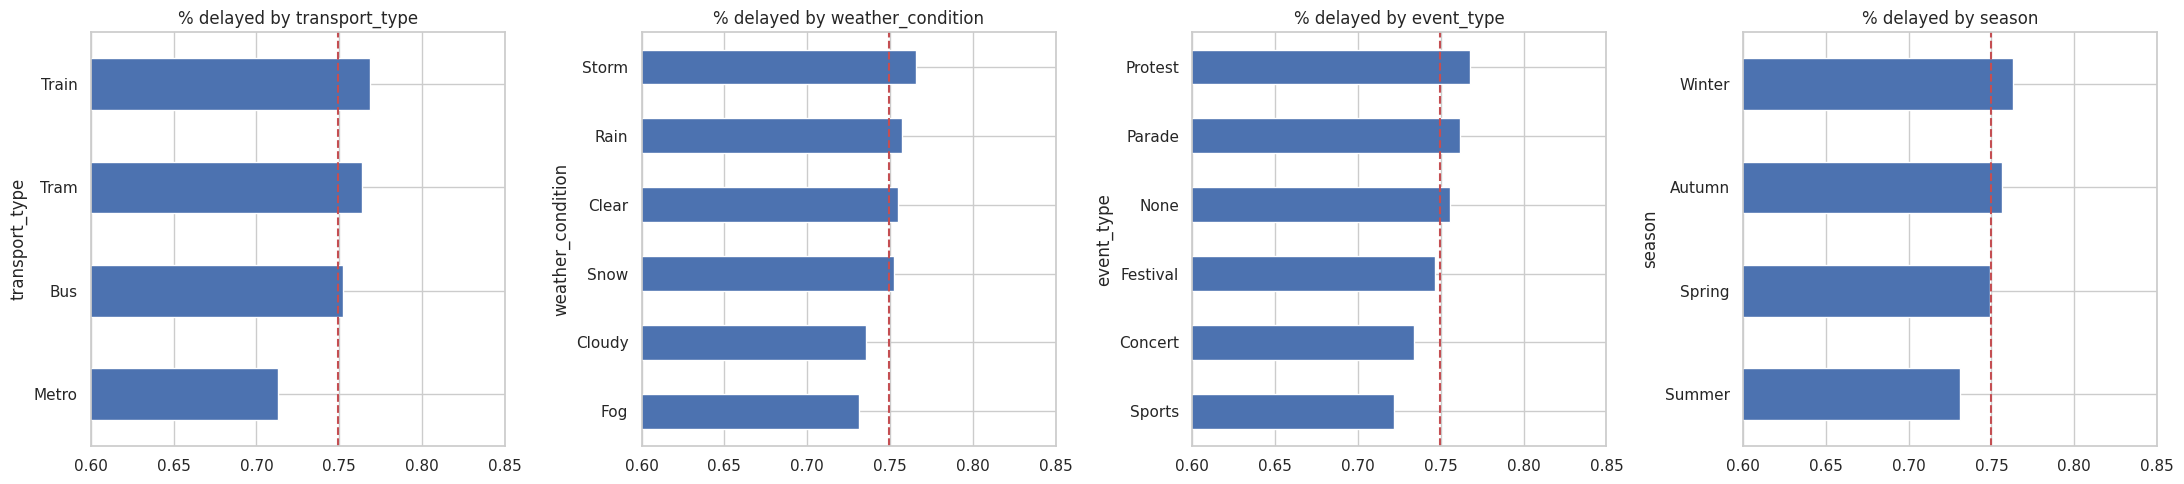

In [13]:
# categorical features vs target
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, i in zip(axes, categories):
    df.groupby(i)['delayed'].mean().sort_values().plot.barh(ax=ax)
    ax.axvline(df['delayed'].mean(), color='r', ls='--')
    ax.set_xlim(0.6, 0.85)
    ax.set_title(f"% delayed by {i}")
plt.tight_layout()
plt.show()

- All bars are close to the red line (overall 75%), so none of the categorical features separates delayed from on-time trips well.

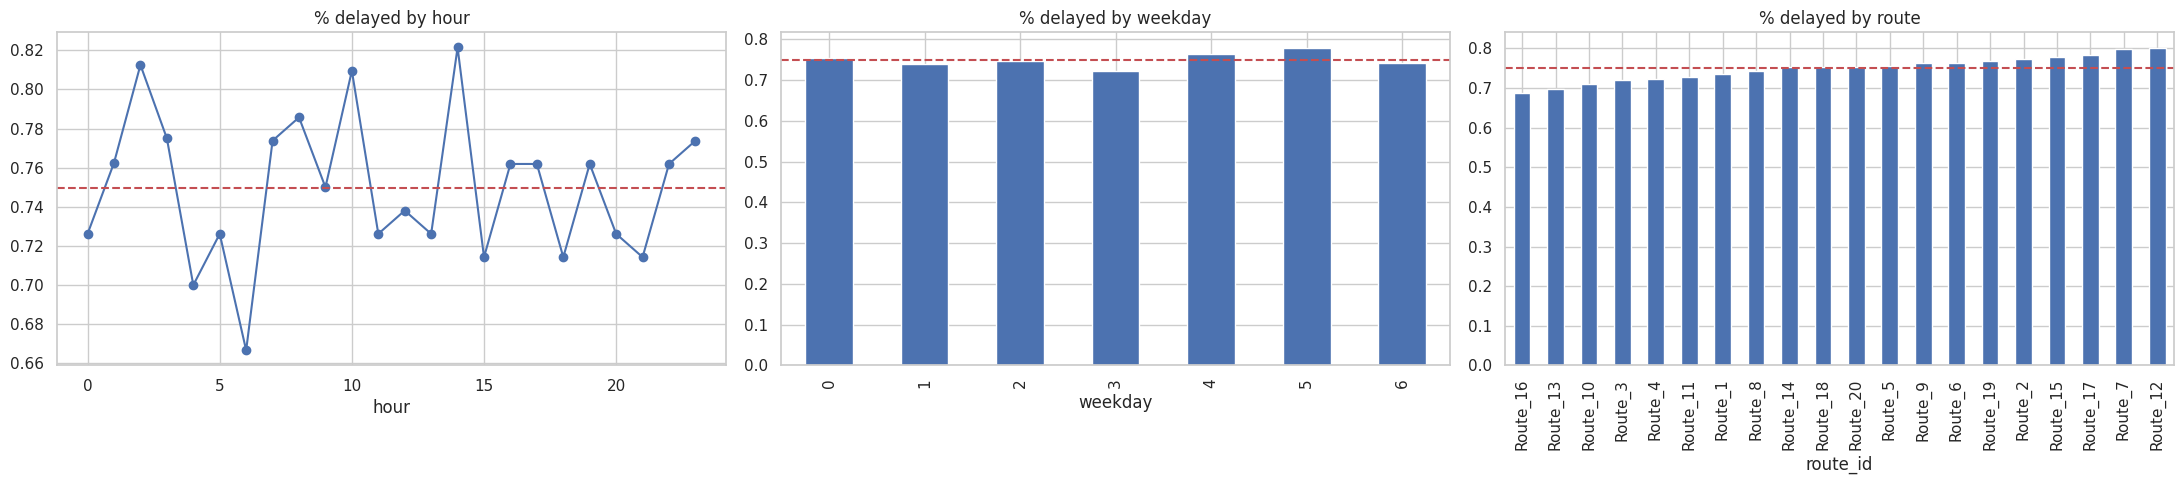

(peak_hour
 0    0.749
 1    0.750
 Name: delayed, dtype: float64,
 holiday
 0    0.747
 1    0.777
 Name: delayed, dtype: float64)

In [14]:
# time-related features vs target
fig, axes = plt.subplots(1, 3, figsize=(22, 5))
df.groupby('hour')['delayed'].mean().plot(marker='o', ax=axes[0]); axes[0].set_title('% delayed by hour')
df.groupby('weekday')['delayed'].mean().plot.bar(ax=axes[1]); axes[1].set_title('% delayed by weekday')
df.groupby('route_id')['delayed'].mean().sort_values().plot.bar(ax=axes[2]); axes[2].set_title('% delayed by route')
for ax in axes: ax.axhline(df['delayed'].mean(), color='r', ls='--')
plt.tight_layout()
plt.show()

df.groupby(['peak_hour'])['delayed'].mean().round(3), df.groupby(['holiday'])['delayed'].mean().round(3)

- Hour of day: the delay rate moves between about 67% and 82% with no clear pattern; with only ~80 trips per hour, this is mostly random noise.
- Peak hour (75.0% vs 74.9%) makes no difference. Holiday is slightly higher (77.7% vs 74.7%), but with only 179 holiday trips this is not reliable.
- Route: 69% to 80%, but each route has only ~100 trips, so the gap is within expected random variation.

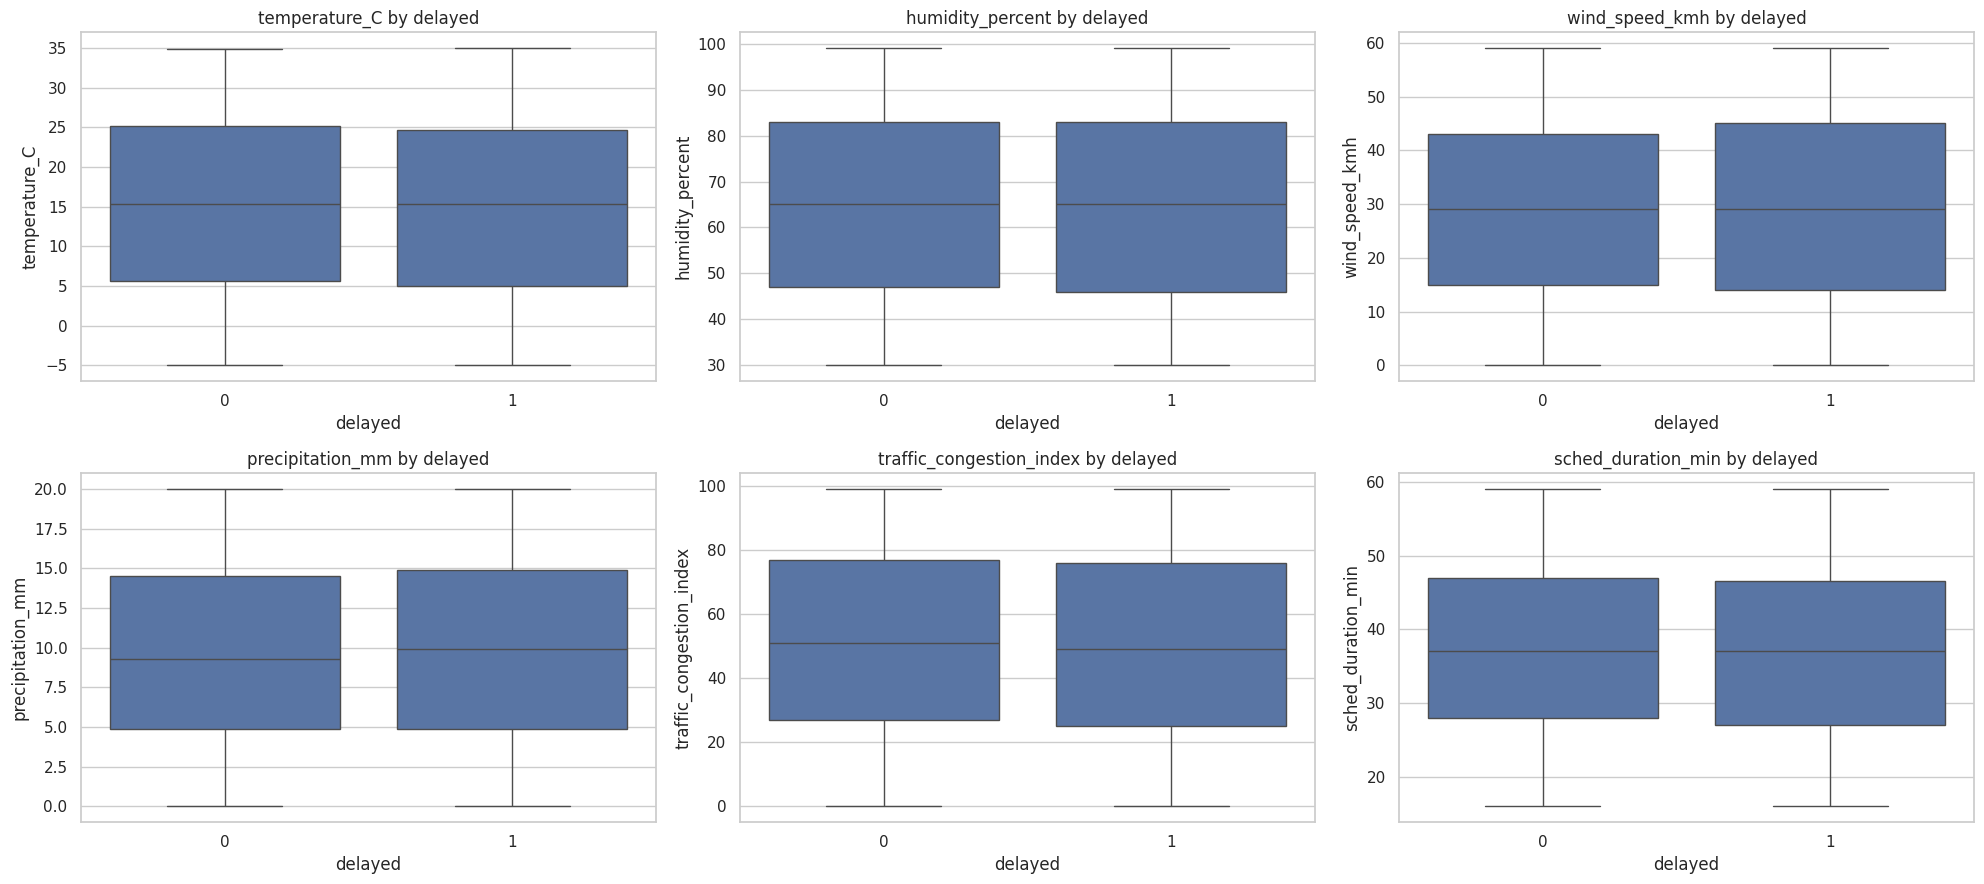

In [15]:
# numeric features vs target
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for ax, i in zip(axes.flatten(), ['temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm', 'traffic_congestion_index', 'sched_duration_min']):
    sns.boxplot(x='delayed', y=i, data=df, ax=ax)
    ax.set_title(f"{i} by delayed")
plt.tight_layout()
plt.show()

- The boxes for delayed (1) and on-time (0) trips almost overlap in every feature, including rain, wind, and traffic congestion.

In [16]:
# correlation between each feature
df.select_dtypes("number").corr()

,actual_departure_delay_min,actual_arrival_delay_min,temperature_C,humidity_percent,wind_speed_kmh,precipitation_mm,event_attendance_est,traffic_congestion_index,holiday,peak_hour,weekday,delayed,hour,day,sched_duration_min
actual_departure_delay_min,1.000000,-0.007161,-0.006968,-0.010783,0.044848,-0.011890,0.010869,0.015072,-0.048676,0.014116,-0.033561,-0.010185,-0.006278,-0.026340,-0.012370
actual_arrival_delay_min,-0.007161,1.000000,-0.039944,-0.027705,-0.007649,0.001106,0.037266,-0.011006,0.033584,0.002784,-0.007785,0.763662,-0.017650,0.001659,-0.012593
temperature_C,-0.006968,-0.039944,1.000000,-0.009675,-0.030514,-0.002967,-0.043716,0.023690,-0.021660,-0.001441,0.025368,-0.010337,-0.018389,-0.001869,0.013849
humidity_percent,-0.010783,-0.027705,-0.009675,1.000000,-0.002398,-0.036747,-0.001325,0.002751,-0.000673,0.010920,0.018173,-0.014377,-0.031379,0.033778,-0.035635
wind_speed_kmh,0.044848,-0.007649,-0.030514,-0.002398,1.000000,0.001786,0.012581,0.009902,-0.019463,0.015984,-0.020725,0.005252,-0.037913,-0.009305,0.024093
precipitation_mm,-0.011890,0.001106,-0.002967,-0.036747,0.001786,1.000000,0.038435,-0.002785,-0.005717,0.012418,-0.018754,0.026295,-0.014854,-0.002367,0.020826
event_attendance_est,0.010869,0.037266,-0.043716,-0.001325,0.012581,0.038435,1.000000,0.013158,0.005104,0.011417,-0.045698,0.003497,0.015756,-0.004240,-0.014325
traffic_congestion_index,0.015072,-0.011006,0.023690,0.002751,0.009902,-0.002785,0.013158,1.000000,0.021720,-0.014065,0.007823,-0.023370,-0.001761,0.026434,0.005281
holiday,-0.048676,0.033584,-0.021660,-0.000673,-0.019463,-0.005717,0.005104,0.021720,1.000000,-0.006644,0.043392,0.019563,0.025533,0.034405,0.056906
peak_hour,0.014116,0.002784,-0.001441,0.010920,0.015984,0.012418,0.011417,-0.014065,-0.006644,1.000000,0.026572,0.000705,0.019834,-0.015572,0.038757


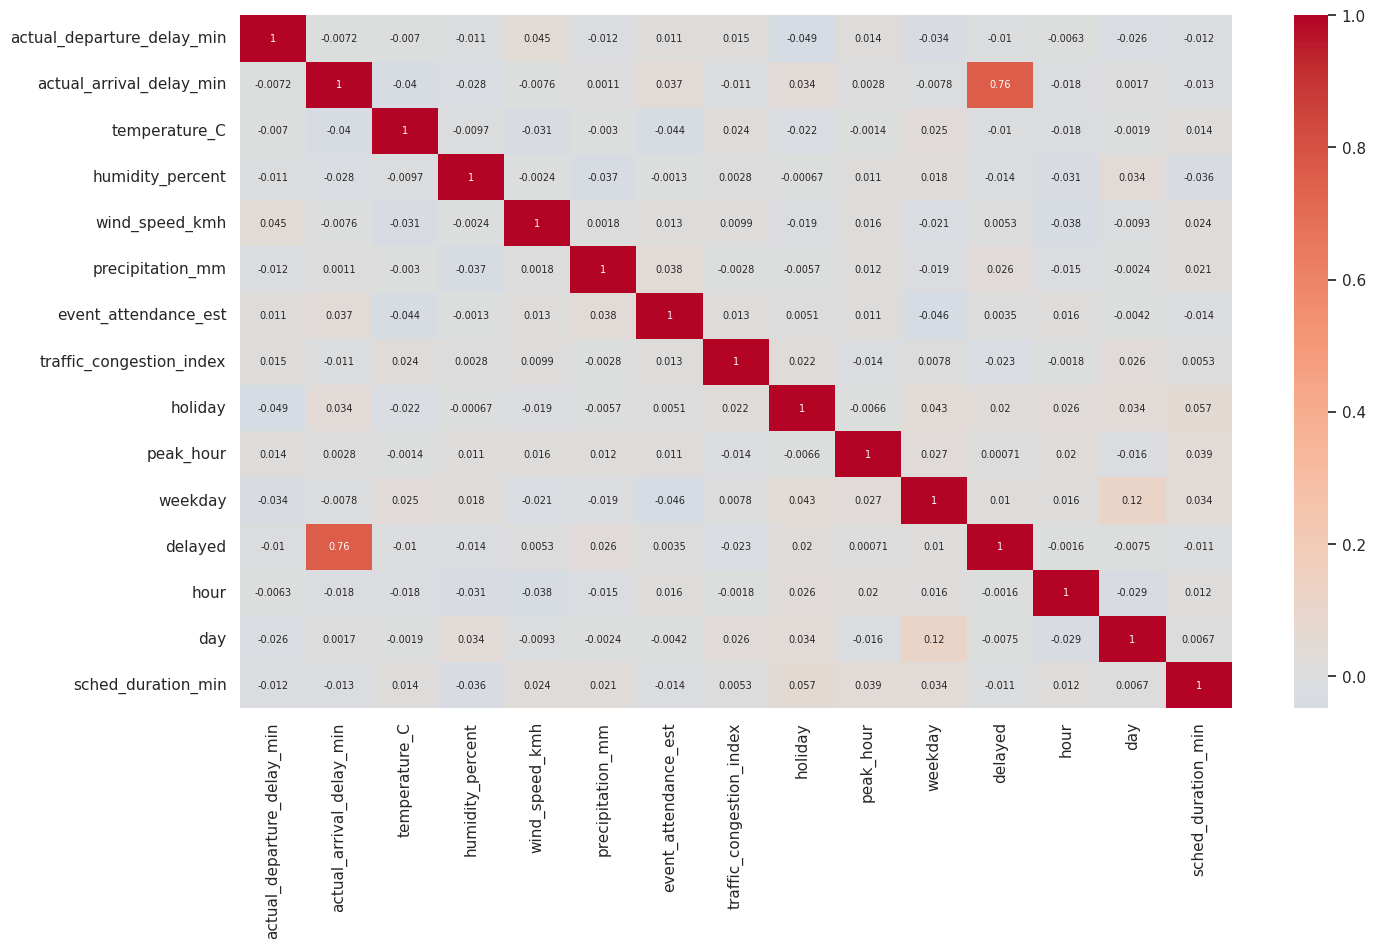

In [17]:
# correlation Matrix Heatmap
plt.figure(figsize=(16, 9))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.show()

- `actual_arrival_delay_min` vs `delayed` (0.76): this is by definition (leakage), not a finding.
- Apart from that, every feature has |correlation| < 0.05 with the delay (for example traffic congestion -0.02, precipitation 0.03, wind 0.01).
- Departure delay vs arrival delay: -0.01, which is unrealistic (a late departure normally leads to a late arrival).

In [18]:
# sanity check on data consistency
print(pd.crosstab(df['season'], pd.cut(df['temperature_C'], [-6, 5, 15, 25, 36], labels=['<=5', '5-15', '15-25', '>25'])))
print("\nMean temperature by weather:\n", df.groupby('weather_condition')['temperature_C'].mean().round(1))
print("\nMean precipitation by weather:\n", df.groupby('weather_condition')['precipitation_mm'].mean().round(1))

temperature_C  <=5  5-15  15-25  >25
season                              
Autumn         121   121    123  115
Spring         123   133    126  120
Summer         122   114    144  144
Winter         131   123    126  114

Mean temperature by weather:
 weather_condition
Clear     15.5
Cloudy    15.3
Fog       16.1
Rain      15.1
Snow      15.2
Storm     13.6
Name: temperature_C, dtype: float64

Mean precipitation by weather:
 weather_condition
Clear      9.4
Cloudy    10.1
Fog        9.6
Rain      10.2
Snow       9.8
Storm     10.2
Name: precipitation_mm, dtype: float64


- Winter still has 114 trips above 25 degrees (Summer has 144), "Snow" is not colder than "Clear" (mean 15.2 vs 15.5 degrees), and "Clear" days have about as much precipitation (9.4 mm) as "Rain" days (10.2 mm).
- These patterns strongly suggest the dataset is **synthetic** (variables generated independently), which matters for how we read the model results.

In [19]:
# check class balance
df["delayed"].value_counts(normalize=True)

delayed
1    0.7495
0    0.2505
Name: proportion, dtype: float64

The classes are imbalanced (75% delayed, 25% on time), so `class_weight='balanced'` is used and accuracy must be compared with the 75% majority baseline.

## Modeling

In [20]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score

In [21]:
# split (delay columns are removed to avoid target leakage)
X = df.drop(['delayed', 'actual_arrival_delay_min', 'actual_departure_delay_min'], axis=1)
y = df['delayed']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [22]:
categorical_cols = ['transport_type', 'route_id', 'origin_station', 'destination_station', 'weather_condition', 'event_type', 'season']
numerical_cols = [col for col in X.columns if col not in categorical_cols]

# Pipeline for numerical feature
num_transformer = Pipeline(steps=[('scaler', StandardScaler())])

# Pipeline for categorical feature (One-Hot, not LabelEncoder, because there is no real order)
cat_transformer = Pipeline(steps=[('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

# Merge preprocessor
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, numerical_cols),
    ('cat', cat_transformer, categorical_cols)
])

# Pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42))
])

model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)
y_proba = model_pipeline.predict_proba(X_test)[:, 1]

## Evaluate

In [23]:
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy Score: 0.75
ROC-AUC: 0.478

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       100
           1       0.75      1.00      0.86       300

    accuracy                           0.75       400
   macro avg       0.38      0.50      0.43       400
weighted avg       0.56      0.75      0.64       400



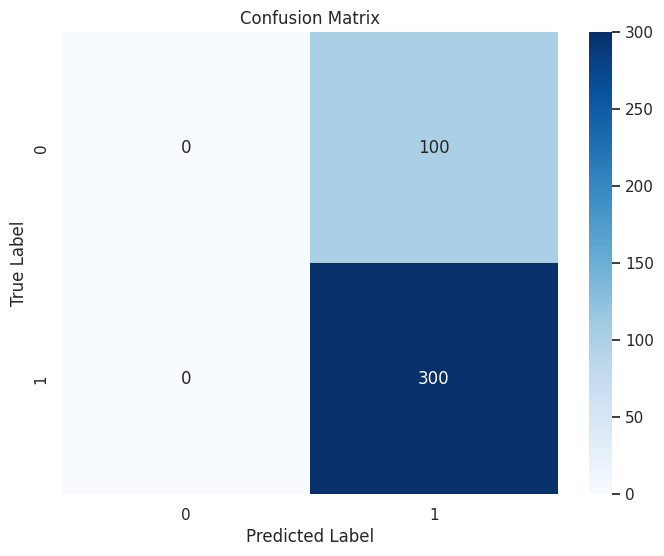

In [24]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [25]:
# check overfit/underfit
train_score = model_pipeline.score(X_train, y_train)
val_score = cross_val_score(model_pipeline, X_train, y_train, cv=5).mean()

print(f"Train: {train_score:.2f}")
print(f"Validation: {val_score:.2f}")

Train: 1.00
Validation: 0.75


The Random Forest fits the training data perfectly (1.00) but on unseen data it only reaches the baseline (0.75) by predicting "delayed" for every trip (recall for on-time trips is 0). This is **overfitting to noise**: there is no real pattern to learn. Next, we compare it against a baseline and other models.

In [26]:
# compare with baseline and other models (5-fold stratified CV)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
models = {
    'Baseline (majority class)': DummyClassifier(strategy='prior'),
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}
rows = []
for name, m in models.items():
    p = Pipeline([('preprocessor', preprocessor), ('classifier', m)])
    rows.append((name,
                 cross_val_score(p, X, y, cv=cv, scoring='accuracy').mean(),
                 cross_val_score(p, X, y, cv=cv, scoring='f1_macro').mean(),
                 cross_val_score(p, X, y, cv=cv, scoring='roc_auc').mean()))
pd.DataFrame(rows, columns=['model', 'accuracy', 'f1_macro', 'roc_auc']).round(3)

,model,accuracy,f1_macro,roc_auc
0,Baseline (majority class),0.750,0.428,0.500
1,Logistic Regression,0.507,0.459,0.474
2,Random Forest,0.750,0.430,0.474
3,Gradient Boosting,0.738,0.446,0.488


- No model beats the baseline: ROC-AUC is about 0.45-0.50 (0.5 = random guessing), and accuracy cannot exceed the 75% obtained by always predicting "delayed".
- A model that predicts "delayed" for everyone gets 75% accuracy but 0% recall for on-time trips, so accuracy alone is misleading here.

In [27]:
# regression check: can the same features predict the arrival delay in minutes?
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
yr = pd.read_csv("/mnt/user-data/uploads/public_transport_delays.csv")['actual_arrival_delay_min']
kf = KFold(5, shuffle=True, random_state=42)
rows = []
for name, m in {'Baseline (mean)': DummyRegressor(), 'Ridge': Ridge(), 'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42)}.items():
    p = Pipeline([('preprocessor', preprocessor), ('model', m)])
    rows.append((name, cross_val_score(p, X, yr, cv=kf, scoring='r2').mean(), -cross_val_score(p, X, yr, cv=kf, scoring='neg_mean_absolute_error').mean()))
pd.DataFrame(rows, columns=['model', 'R2', 'MAE (minutes)']).round(3)

,model,R2,MAE (minutes)
0,Baseline (mean),-0.003,7.954
1,Ridge,-0.096,8.235
2,Random Forest,-0.046,8.092


R² is 0 or negative for every model, so the features also cannot predict the delay in minutes.

## Conclusion
1. **No predictive signal.** Weather, events, traffic, peak hour, route, and transport type show no meaningful relationship with delays (all correlations < 0.05, all statistical differences within random noise). Models perform at or below baseline (ROC-AUC about 0.5, R² about 0).
2. **Accuracy of 75% is misleading.** It equals the share of delayed trips, i.e. just predicting "delayed" every time. This model should not be used for operational decisions.
3. **Dataset is likely synthetic** (temperature unrelated to season, rain on clear days, departure delay unrelated to arrival delay, event attendance unrelated to event type), and covers only 22 days.
4. **Pitfalls avoided:** delay columns are not used as features (target leakage), empty `event_type` is kept as its own "None" category (not filled with the mode) after checking that it does not reliably mean "no event", and One-Hot Encoding replaces LabelEncoder on nominal columns.
5. **Next steps:** use real data over a longer period, add history-based features (previous delay on the same route/station), and check per-class recall instead of accuracy only.